## Imports and Constants

In [68]:
import copy

from rdkit import Chem
from rdkit.Chem import Draw, AllChem

from ase import Atoms
from ase.optimize import FIRE2

from tblite.ase import TBLite
from mace.calculators import MACECalculator

from PIL import Image

import numpy as np

from openff.toolkit import Molecule, Topology
from openff.nagl import GNNModel
from openff.nagl_models import list_available_nagl_models
from openff.units import unit
from openff.toolkit.typing.engines.smirnoff import ForceField, get_available_force_fields
from openff.interchange import Interchange

import openmm

GNN_MODEL_PATH = list_available_nagl_models()[-1]
GNN_MODEL = GNNModel.load(GNN_MODEL_PATH)

ETKDG_PARAMS = AllChem.ETKDGv3()
ETKDG_PARAMS.randomSeed = 1994
ETKDG_PARAMS.maxIterations = 1000
ETKDG_PARAMS.useRandomCoords = True

MOL_NAME_PREFIX = "TAF"
N_MONOMERS = 1

In [69]:
list_available_nagl_models()

[PosixPath('/home/fazekaszs/miniforge3/envs/science/lib/python3.12/site-packages/openff/nagl_models/models/am1bcc/openff-gnn-am1bcc-0.0.1-alpha.1.pt'),
 PosixPath('/home/fazekaszs/miniforge3/envs/science/lib/python3.12/site-packages/openff/nagl_models/models/am1bcc/openff-gnn-am1bcc-0.1.0-rc.1.pt'),
 PosixPath('/home/fazekaszs/miniforge3/envs/science/lib/python3.12/site-packages/openff/nagl_models/models/am1bcc/openff-gnn-am1bcc-0.1.0-rc.2.pt'),
 PosixPath('/home/fazekaszs/miniforge3/envs/science/lib/python3.12/site-packages/openff/nagl_models/models/am1bcc/openff-gnn-am1bcc-0.1.0-rc.3.pt'),
 PosixPath('/home/fazekaszs/miniforge3/envs/science/lib/python3.12/site-packages/openff/nagl_models/models/am1bcc/openff-gnn-am1bcc-1.0.0.pt')]

Select the molecule to be used:

In [70]:
if MOL_NAME_PREFIX == "HEP":
    MOL_SMILES = (
        "O1[C@H](COS(=O)(=O)[O-])[C@@H](O[*:1])[C@H](O)[C@@H](NS(=O)(=O)[O-])[C@H]1"  # ring 1, [*:1] is the attach point
        "O"  # bridge O
        "[C@H]2[C@H](O)[C@@H](OS(=O)(=O)[O-])[C@@H]([*:2])O[C@H]2(C(=O)([O-]))"  # ring 2, [*:2] is the attach point, base C has inverted chirality!
    )
elif MOL_NAME_PREFIX == "PST":
    MOL_SMILES = (
        "[*:1]C[C@H](c1ccccc1)C[C@@H]([*:2])c1ccccc1"
    )
elif MOL_NAME_PREFIX == "PEG":
    MOL_SMILES = (
        "[*:1]CCO[*:2]"
    )
elif MOL_NAME_PREFIX == "PAC":
    MOL_SMILES = (
        "[*:1]C#C[*:2]"
    )
elif MOL_NAME_PREFIX == "TAF":
    MOL_SMILES = (
        "O=C([O-])c3c([*:1])cc1nc(oc1c3)-c2c([*:2])c(Cl)cc(Cl)c2"
    )
else:
    raise Exception("Invalid molecule name!")

## Convenience Functions

In [71]:
def create_polymer(n_members: int) -> Chem.Mol:

    # Create a monomer unit
    monomer = Chem.MolFromSmiles(MOL_SMILES)

    # Create an object names polymer, which will be grown progressively
    polymer = copy.deepcopy(monomer)

    # Calculate monomer size, start and end atom indices
    monomer_size = monomer.GetNumAtoms()
    start_atom_idx, end_atom_idx = [
        idx for idx, atom in enumerate(polymer.GetAtoms())
        if atom.GetSmarts() in {"[*:1]", "[*:2]"}
    ]

    # Close one end of the polymer object
    e_polymer = Chem.EditableMol(polymer)
    e_polymer.ReplaceAtom(start_atom_idx, Chem.Atom(1))
    polymer = e_polymer.GetMol()

    # Add new monomer units progressively
    for progress in range(n_members - 1):

        # Add a new monomer element
        new_polymer = Chem.CombineMols(polymer, monomer)

        # Determine the atom indices for the new bond
        # - this is the index of the atom to which [*:2] is bound in the preceeding polymer
        atom1_idx = polymer.GetAtomWithIdx(
            progress * monomer_size + end_atom_idx
        ).GetNeighbors()[0].GetIdx()  
        # - this is the index of the atom to which [*:1] is bound in the newly added monomer
        atom2_idx = polymer.GetNumAtoms() + monomer.GetAtomWithIdx(
            start_atom_idx
        ).GetNeighbors()[0].GetIdx()

        # Convert the Mol object to EditableMol and add the new bond
        e_polymer = Chem.EditableMol(new_polymer)    
        e_polymer.AddBond(
            atom1_idx, atom2_idx,
            Chem.BondType.SINGLE
        ) 
        # IMPORTANT NOTE ON CHIRALITY:
        # the chirality of the carbon connected to [*:2] is inverted in the SMILES wrt. the "correct"
        # HEPARIN_SMILES, because during bond addition (above) and dummy atom removal (below) the centrum
        # gets inverted!
    
        # Convert the EditableMol object to Mol
        new_polymer = e_polymer.GetMol()
        polymer = new_polymer
        
    # Close the other end of the polymer object
    e_polymer = Chem.EditableMol(polymer)
    e_polymer.ReplaceAtom((n_members - 1) * monomer_size + end_atom_idx, Chem.Atom(1))
    polymer = e_polymer.GetMol()

    # Remove dummy atoms
    polymer = Chem.DeleteSubstructs(polymer, Chem.MolFromSmarts("[#0]"))
    
    return polymer

In [72]:
def optimize_molecule_coordinates(mol: Chem.Mol, run_xtb: bool = False) -> Chem.Mol:

    optimized_mol = Chem.AddHs(mol)
    Chem.SanitizeMol(mol)

    # Conformer generation and classical FF optimization
    AllChem.EmbedMolecule(optimized_mol, ETKDG_PARAMS)

    with open("etkdg_embedded.mol", "w") as f:
        f.write(Chem.MolToMolBlock(optimized_mol))
    
    AllChem.MMFFOptimizeMolecule(optimized_mol)

    with open("mmff_optimized.mol", "w") as f:
        f.write(Chem.MolToMolBlock(optimized_mol))

    if run_xtb:

        # Building the ASE system
        conf = optimized_mol.GetConformer()
        atomic_numbers, positions = list(), list()
        for atom in optimized_mol.GetAtoms():
            atom_position = conf.GetAtomPosition(atom.GetIdx())
            positions.append([atom_position.x, atom_position.y, atom_position.z])
            atomic_numbers.append(atom.GetAtomicNum())
        
        atoms = Atoms(numbers=atomic_numbers, positions=positions)
    
        # MACE optimization
        # atoms.calc = MACECalculator(model_paths="./MACE-OFF23_small.model", device="cuda")
        # FIRE2(
        #     atoms, 
        #     logfile="mace_opt.log",
        #     trajectory="mace_opt.pckl",
        #     restart="mace_opt_restart.json"
        # ).run(fmax=0.05)
    
        # TBLite GFN2-xTB optimization
        atoms.calc = TBLite(
            method="GFN2-xTB", 
            charge=Chem.GetFormalCharge(mol),
            verbosity=0, 
            max_iterations=1000
        )
        FIRE2(
            atoms, 
            logfile="tblite_gfn2_opt.log",
            trajectory="tblite_gfn2_opt.pckl",
            restart="mace_opt_restart.json"
        ).run(fmax=0.1, steps=1000)
    
        # Transfer of coordinates back to the RDKit world
        opt_positions = atoms.get_positions()
        for i in range(optimized_mol.GetNumAtoms()):
            x, y, z = opt_positions[i]
            conf.SetAtomPosition(i, (float(x), float(y), float(z)))
    
        with open("xtb_optimized.mol", "w") as f:
            f.write(Chem.MolToMolBlock(optimized_mol))

    return optimized_mol

## Creating the Polymer Instance

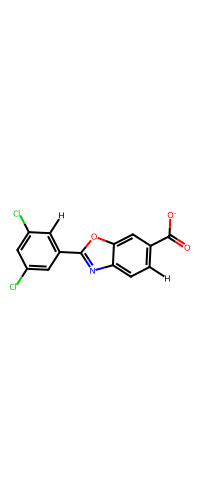

In [73]:
mol = create_polymer(N_MONOMERS)
Chem.SanitizeMol(mol)
AllChem.Compute2DCoords(mol)
Draw.MolToFile(mol, "polymer.png", size=(200 * N_MONOMERS, 500))
Image.open("polymer.png")

In [74]:
optimized_mol = optimize_molecule_coordinates(mol, run_xtb = False)

## OpenFF Operations

### Charge Assignation and Checks

In [75]:
optimized_mol_openff = Molecule.from_rdkit(optimized_mol)
nagl_charges = GNN_MODEL.compute_properties(optimized_mol_openff, check_domains=True)
optimized_mol_openff.partial_charges = nagl_charges["am1bcc_charges"] * unit.elementary_charge

[13:49:45] WARNING: Proton(s) added/removed



In [76]:
np.array(optimized_mol_openff.conformers[0].m, dtype=float)

array([[-1.62021059, -5.10007622,  3.22854665],
       [-2.10339379, -4.05839292,  2.68504183],
       [-3.29811581, -3.64110361,  2.79754718],
       [-1.16676029, -3.23445283,  1.82013592],
       [ 0.17725147, -3.62990761,  1.64365036],
       [ 0.52413094, -4.53660578,  2.14103503],
       [ 1.0750131 , -2.89470896,  0.85144484],
       [ 0.59984895, -1.73691058,  0.22694647],
       [ 1.22766638, -0.82854267, -0.59306465],
       [ 0.277247  ,  0.04607963, -0.86973213],
       [-0.93625255, -0.21880511, -0.29073107],
       [-0.72176328, -1.36780508,  0.41382145],
       [-1.63793126, -2.06640112,  1.18740075],
       [ 0.35557716,  1.24300583, -1.70320171],
       [ 1.57027166,  1.57117234, -2.32530365],
       [ 2.44002755,  0.93136584, -2.18048087],
       [ 1.6697844 ,  2.70885284, -3.12578503],
       [ 3.16807434,  3.09460354, -3.88028894],
       [ 0.56894045,  3.536836  , -3.32136044],
       [-0.63829073,  3.21683736, -2.70722876],
       [-2.00576619,  4.23557356, -2.943

In [77]:
optimized_mol.GetNumAtoms() == len(optimized_mol_openff.atoms)

True

In [78]:
total_charge = np.sum(nagl_charges["am1bcc_charges"])
print(f"Total charge: {total_charge:.5f}")

Total charge: -1.00000


In [79]:
sulfate_group = Chem.MolFromSmarts("OS(=O)(=O)([O-])")
sulfamate_group = Chem.MolFromSmarts("[N:1]([H:2])S(=O)(=O)([O-])")
carboxylate_group = Chem.MolFromSmarts("C(=O)([O-])")

sulfate_matches = optimized_mol.GetSubstructMatches(sulfate_group)
sulfamate_matches = optimized_mol.GetSubstructMatches(sulfamate_group)
carboxylate_matches = optimized_mol.GetSubstructMatches(carboxylate_group)

for indices in sulfate_matches:
    group_charge = np.sum(nagl_charges["am1bcc_charges"][np.array(indices)])
    print(f"Total charge of a sulfate group {indices} = {group_charge:.5f}")
    
for indices in sulfamate_matches:
    group_charge = np.sum(nagl_charges["am1bcc_charges"][np.array(indices)])
    print(f"Total charge of a sulfamate group {indices} = {group_charge:.5f}")
    
for indices in carboxylate_matches:
    group_charge = np.sum(nagl_charges["am1bcc_charges"][np.array(indices)])
    print(f"Total charge of a carboxylate group {indices} = {group_charge:.5f}")

Total charge of a carboxylate group (1, 0, 2) = -0.73570


Total charge of monomer subunit number 0 = -1.32221
Total charge of monomer subunit number 1 = -1.32221


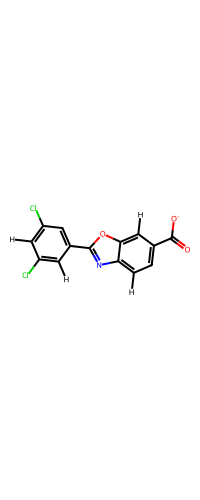

In [80]:
monomer_substructure = Chem.MolFromSmiles(MOL_SMILES)
monomer_substructure = Chem.AddHs(monomer_substructure)
monomer_substructure = Chem.DeleteSubstructs(monomer_substructure, Chem.MolFromSmarts("[#0]"))

AllChem.Compute2DCoords(monomer_substructure)
Draw.MolToFile(monomer_substructure, "monomer_substructure.png", size=(200, 500))

monomer_matches = optimized_mol.GetSubstructMatches(monomer_substructure)

for subunit_idx, indices in enumerate(monomer_matches):
    group_charge = np.sum(nagl_charges["am1bcc_charges"][np.array(indices)])
    print(f"Total charge of monomer subunit number {subunit_idx} = {group_charge:.5f}")
Image.open("monomer_substructure.png")

## Conversion to a GROMACS Compatible Format

In [81]:
# Rename atoms, so that they have unique names
counters = {atom.symbol: 0 for atom in optimized_mol_openff.atoms}
for atom in optimized_mol_openff.atoms:
    element = atom.symbol
    counters[element] += 1
    atom.name = f"{element}{counters[element]}"

In [82]:
# Create an interchange object, from which we can extract the potential energy terms
ff = ForceField("openff-2.2.0.offxml")
top = Topology.from_molecules([optimized_mol_openff, ])
optimized_mol_interchange = Interchange.from_smirnoff(
    ff, top,
    charge_from_molecules=[optimized_mol_openff, ],
    box=np.array([5., 5., 5.]) * unit.nanometer
)

/home/fazekaszs/miniforge3/envs/science/lib/python3.12/site-packages/openff/interchange/components/interchange.py:1119: FutureWarning: `torch.distributed.reduce_op` is deprecated, please use `torch.distributed.ReduceOp` instead
  if isinstance(obj, functools._lru_cache_wrapper) and obj.__module__.startswith("openff.interchange"):


__Important notes on the interchange object__:
- it can be indexed with the following strings: `{"vdW", "Electrostatics", "Bonds", "Angles", "ProperTorsions", "ImproperTorsions"}`,
- every such indexing has a field called _potentials_, which is a dictionary of pot_keys and pot_values,
- a pot_key determines the type of the potential, i.e. contains information about the molecular subgraph it has been assigned to
  (`pot_key.id` field),
- a pot_value contains the parameters assigned to that potential (`pot_value.parameters` field),
- the parameters field can be indexed with parameter names
  (e.g. for a `"vdW"` type potential the `{"sigma", "epsilon"}` keys are available),
- masses are stored atom-wise, uniquely to each atom in `[atom.mass for atom in optimized_mol_interchange.topology.atoms]`,
- every interchange indexing also has a field called _key_map_, which contains the atom index tuple to potential key assignation, i.e.
  `interchange["Bonds"].key_map` = `BondKey(idx1, idx2)` + `PotentialKey` pairs __AND__
  `interchange["Bonds"].potentials` = `PotentialKey` + parameters pairs,
- Proper- and ImproperTorsions contain a parameter called _idivf_, which is a divisor of the _k_ force constant

In [83]:
# Print out the nonbonded parameters
# Also, assign an atom type to every nonbonded parameter
# Create a mapping from the vdW pot_keys to the atom types

vdw_to_atom_type = dict()
for pot_idx, (pot_key, pot) in enumerate(optimized_mol_interchange["vdW"].potentials.items()):
    current_atom_type = f"{MOL_NAME_PREFIX}_T{pot_idx}"
    vdw_to_atom_type[pot_key] = current_atom_type
    print(f"{current_atom_type:10s}: sigma = {pot.parameters['sigma']:5f}, epsilon = {pot.parameters['epsilon']:5f}")


TAF_T0    : sigma = 3.039812 angstrom, epsilon = 0.210206 kilocalorie / mole
TAF_T1    : sigma = 3.480647 angstrom, epsilon = 0.086879 kilocalorie / mole
TAF_T2    : sigma = 2.572582 angstrom, epsilon = 0.015611 kilocalorie / mole
TAF_T3    : sigma = 3.206876 angstrom, epsilon = 0.167692 kilocalorie / mole
TAF_T4    : sigma = 3.025106 angstrom, epsilon = 0.168465 kilocalorie / mole
TAF_T5    : sigma = 3.307528 angstrom, epsilon = 0.265600 kilocalorie / mole


Create the `[ atoms ]` directive in the rtp file, the new records in `atomtypes.dat` and the new records in `ffnonbonded.itp`:

In [84]:
rtp_field_atoms = [
    [atom.name, None, None, ] 
    for atom in optimized_mol_interchange.topology.molecule(0).atoms
]
ffnonbonded_records = {atom_type: [None, None, None, None] for atom_type in vdw_to_atom_type.values()}

# Assign atom types to atoms, and assign ffnonbonded parameters to the atomtypes
for atom_indices, potential_key in optimized_mol_interchange["vdW"].key_map.items():

    # Atom type assignation to the current atom
    current_atom_type = vdw_to_atom_type[potential_key]
    current_atom_index = atom_indices.atom_indices[0]
    rtp_field_atoms[current_atom_index][1] = current_atom_type

    # Get the corresponding vdW parameters
    vdw_params = optimized_mol_interchange["vdW"].potentials[potential_key].parameters

    # Atomic number, mass, and vdW parameter assignation to the current atom type
    current_atom_num = optimized_mol_interchange.topology.molecule(0).atoms[current_atom_index].atomic_number
    current_atom_mass = optimized_mol_interchange.topology.molecule(0).atoms[current_atom_index].mass.m
    if ffnonbonded_records[current_atom_type][0] is None:
        ffnonbonded_records[current_atom_type][0] = current_atom_num
        ffnonbonded_records[current_atom_type][1] = current_atom_mass
        ffnonbonded_records[current_atom_type][2] = vdw_params["sigma"].m_as("nanometer")
        ffnonbonded_records[current_atom_type][3] = vdw_params["epsilon"].m_as("kilojoule / mol")
    else:
        err_msg = f"Multiple assignation found for atom idx {current_atom_index}!"
        assert ffnonbonded_records[current_atom_type][0] == current_atom_num, err_msg

# Fill charges
for atom_indices, potential_key in optimized_mol_interchange["Electrostatics"].key_map.items():
    charge = optimized_mol_interchange["Electrostatics"].potentials[potential_key].parameters["charge"].m
    rtp_field_atoms[atom_indices.this_atom_index][2] = charge

# Create the strings that will go into the forcefield
rtp_field_atoms_str = " [ atoms ]\n" + "\n".join(
    f"  {f1:10s} {f2:10s} {f3:10.6f} {idx+1:6d}" 
    for idx, (f1, f2, f3) in enumerate(rtp_field_atoms)
)
# print(rtp_field_atoms_str)

atp_field_masses_str = "\n".join(
    f"{atom_type:10s} {f2:8.5f}"
    for atom_type, (_, f2, _, _) in ffnonbonded_records.items()
)
# print(atp_field_masses_str)

ffnonbonded_records_str = "\n".join(
    f"{atom_type:10s} {f1:6d} {f2:10.6f} {0.:6.4f} A {f3:.5e} {f4:.5e}"
    for atom_type, (f1, f2, f3, f4) in ffnonbonded_records.items()
)
# print(ffnonbonded_records_str)

Create the bonded parameter parts (`[ bonds ]`, `[ angles ]`, `[ dihedrals ]` and `[ impropers ]`) in the rtp file:

In [85]:
rtp_field_bonds = list()
for atom_indices, potential_key in optimized_mol_interchange["Bonds"].key_map.items():

    current_potential = optimized_mol_interchange["Bonds"].potentials[potential_key].parameters
    rtp_field_bonds.append([
        rtp_field_atoms[atom_indices.atom_indices[0]][0],
        rtp_field_atoms[atom_indices.atom_indices[1]][0],
        current_potential["length"].m_as("nanometer"),
        current_potential["k"].m_as("kilojoule / mol / nanometer**2"),
    ])
    
rtp_field_bonds_str = " [ bonds ]\n" + "\n".join(
    f"  {f1:10s} {f2:10s} {f3:10.6f} {f4:10.6f}"
    for f1, f2, f3, f4 in rtp_field_bonds
)
# print(rtp_field_bonds_str)

rtp_field_angles = list()
for atom_indices, potential_key in optimized_mol_interchange["Angles"].key_map.items():

    current_potential = optimized_mol_interchange["Angles"].potentials[potential_key].parameters
    rtp_field_angles.append([
        rtp_field_atoms[atom_indices.atom_indices[0]][0],
        rtp_field_atoms[atom_indices.atom_indices[1]][0],
        rtp_field_atoms[atom_indices.atom_indices[2]][0],
        current_potential["angle"].m_as("degree"),
        current_potential["k"].m_as("kilojoule / mol / radian**2"),
    ])

rtp_field_angles_str = " [ angles ]\n" + "\n".join(
    f"  {f1:10s} {f2:10s} {f3:10s} {f4:10.6f} {f5:10.6f}"
    for f1, f2, f3, f4, f5 in rtp_field_angles
)
# print(rtp_field_angles_str)

rtp_field_dihedrals = list()
for atom_indices, potential_key in optimized_mol_interchange["ProperTorsions"].key_map.items():

    current_potential = optimized_mol_interchange["ProperTorsions"].potentials[potential_key].parameters
    rtp_field_dihedrals.append([
        rtp_field_atoms[atom_indices.atom_indices[0]][0],
        rtp_field_atoms[atom_indices.atom_indices[1]][0],
        rtp_field_atoms[atom_indices.atom_indices[2]][0],
        rtp_field_atoms[atom_indices.atom_indices[3]][0],
        current_potential["phase"].m_as("degree"),
        current_potential["k"].m_as("kilojoule / mol") / current_potential["idivf"].m,
        current_potential["periodicity"].m,
    ])
    
rtp_field_dihedrals_str = " [ dihedrals ]\n" + "\n".join(
    f"  {f1:10s} {f2:10s} {f3:10s} {f4:10s} {f5:10.6f} {f6:10.6f} {f7:6d}"
    for f1, f2, f3, f4, f5, f6, f7 in rtp_field_dihedrals
)
# print(rtp_field_dihedrals_str)

rtp_field_impropers = list()
for atom_indices, potential_key in optimized_mol_interchange["ImproperTorsions"].key_map.items():

    current_potential = optimized_mol_interchange["ImproperTorsions"].potentials[potential_key].parameters
    rtp_field_impropers.append([
        rtp_field_atoms[atom_indices.atom_indices[0]][0],
        rtp_field_atoms[atom_indices.atom_indices[1]][0],
        rtp_field_atoms[atom_indices.atom_indices[2]][0],
        rtp_field_atoms[atom_indices.atom_indices[3]][0],
        current_potential["phase"].m_as("degree"),
        current_potential["k"].m_as("kilojoule / mol") / current_potential["idivf"].m,
        current_potential["periodicity"].m,
    ])
    
rtp_field_impropers_str = " [ impropers ]\n" + "\n".join(
    f"  {f1:10s} {f2:10s} {f3:10s} {f4:10s} {f5:10.6f} {f6:10.6f} {f7:6d}"
    for f1, f2, f3, f4, f5, f6, f7 in rtp_field_impropers
)
# print(rtp_field_impropers_str)

Bring all rtp components together:

In [86]:
bonded_types_definition = """
[ bondedtypes ]
; Col 1: Type of bond
; Col 2: Type of angles
; Col 3: Type of proper dihedrals
; Col 4: Type of improper dihedrals
; Col 5: Generate all dihedrals if 1, only heavy atoms of 0.
; Col 6: Number of excluded neighbors for nonbonded interactions
; Col 7: Generate 1,4 interactions between pairs of hydrogens if 1
; Col 8: Remove impropers over the same bond as a proper if it is 1
; bonds  angles  dihedrals  impropers all_dihedrals nrexcl HH14 RemoveDih
     1       1          9          4        1         3      1     0

"""

full_rtp_str = (
    bonded_types_definition + f"[ {MOL_NAME_PREFIX} ]\n" + 
    rtp_field_atoms_str + "\n" + 
    rtp_field_bonds_str + "\n" + 
    rtp_field_angles_str + "\n" + 
    rtp_field_dihedrals_str + "\n" + 
    rtp_field_impropers_str
)

print(full_rtp_str)


[ bondedtypes ]
; Col 1: Type of bond
; Col 2: Type of angles
; Col 3: Type of proper dihedrals
; Col 4: Type of improper dihedrals
; Col 5: Generate all dihedrals if 1, only heavy atoms of 0.
; Col 6: Number of excluded neighbors for nonbonded interactions
; Col 7: Generate 1,4 interactions between pairs of hydrogens if 1
; Col 8: Remove impropers over the same bond as a proper if it is 1
; bonds  angles  dihedrals  impropers all_dihedrals nrexcl HH14 RemoveDih
     1       1          9          4        1         3      1     0

[ TAF ]
 [ atoms ]
  O1         TAF_T0      -0.818811      1
  C1         TAF_T1       0.901919      2
  O2         TAF_T0      -0.818811      3
  C2         TAF_T1      -0.108585      4
  C3         TAF_T1      -0.110323      5
  H1         TAF_T2       0.157487      6
  C4         TAF_T1      -0.103807      7
  C5         TAF_T1       0.036498      8
  N1         TAF_T3      -0.569897      9
  C6         TAF_T1       0.557003     10
  O3         TAF_T4    

In [87]:
optimized_mol_interchange.to_gro(file_path=f"mol_generator_out/{MOL_NAME_PREFIX}.gro")

with open(f"mol_generator_out/{MOL_NAME_PREFIX}.rtp", "w") as f:
    f.write(full_rtp_str)

with open(f"mol_generator_out/{MOL_NAME_PREFIX}_atomtypes.atp", "w") as f:
    f.write(atp_field_masses_str)

with open(f"mol_generator_out/{MOL_NAME_PREFIX}_ffnonbonded.itp", "w") as f:
    f.write(ffnonbonded_records_str)
